In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

train_df = pd.read_csv("/content/sample_data/dataset_B_training.csv")
test_df = pd.read_csv("/content/sample_data/dataset_B_testing.csv")

train_df.columns = train_df.columns.str.strip()
test_df.columns = test_df.columns.str.strip()

print("Training dataset:", train_df.shape)
print("Testing dataset:", test_df.shape)

display(train_df.head())

Training dataset: (4756, 31)
Testing dataset: (4749, 30)


,respondent_id,h1n1_concern,h1n1_knowledge,behavioral_antiviral_meds,behavioral_avoidance,behavioral_face_mask,behavioral_wash_hands,behavioral_large_gatherings,behavioral_outside_home,behavioral_touch_face,...,income_poverty,marital_status,rent_or_own,employment_status,census_msa,household_adults,household_children,employment_sector,number_chronic_med_conditions,h1n1_vaccine
0,1,1.0,2.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,...,"<= $75,000, Above Poverty",Married,Own,Employed,"MSA, Not Principle City",2.0,1.0,science,0,0
1,2,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,Below Poverty,Not Married,Own,Employed,Non-MSA,0.0,3.0,wholesale,0,0
2,3,2.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,...,"> $75,000",Not Married,Own,Employed,"MSA, Principle City",0.0,0.0,education,0,1
3,4,0.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,...,"<= $75,000, Above Poverty",Not Married,Rent,Not in Labor Force,Non-MSA,0.0,0.0,NaN,0,0
4,5,2.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,NaN,Not Married,NaN,Unemployed,Non-MSA,3.0,0.0,NaN,0,0


In [5]:

print("Dataset Information:")
train_df.info()

print("\nStatistical Summary:")
display(train_df.describe(include="all").T)

print("\nDuplicate Rows:", train_df.duplicated().sum())

print("\nTarget Distribution:")
print(train_df["h1n1_vaccine"].value_counts())


Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4756 entries, 0 to 4755
Data columns (total 31 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   respondent_id                  4756 non-null   int64  
 1   h1n1_concern                   4741 non-null   float64
 2   h1n1_knowledge                 4734 non-null   float64
 3   behavioral_antiviral_meds      4739 non-null   float64
 4   behavioral_avoidance           4729 non-null   float64
 5   behavioral_face_mask           4752 non-null   float64
 6   behavioral_wash_hands          4748 non-null   float64
 7   behavioral_large_gatherings    4747 non-null   float64
 8   behavioral_outside_home        4741 non-null   float64
 9   behavioral_touch_face          4736 non-null   float64
 10  doctor_recc_h1n1               4437 non-null   float64
 11  child_under_6_months           4622 non-null   float64
 12  health_worker              

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
respondent_id,4756.0,NaN,NaN,NaN,2378.5,1373.08327,1.0,1189.75,2378.5,3567.25,4756.0
h1n1_concern,4741.0,NaN,NaN,NaN,1.658933,0.892478,0.0,1.0,2.0,2.0,3.0
h1n1_knowledge,4734.0,NaN,NaN,NaN,1.30714,0.612811,0.0,1.0,1.0,2.0,2.0
behavioral_antiviral_meds,4739.0,NaN,NaN,NaN,0.057396,0.232622,0.0,0.0,0.0,0.0,1.0
behavioral_avoidance,4729.0,NaN,NaN,NaN,0.74096,0.438154,0.0,0.0,1.0,1.0,1.0
behavioral_face_mask,4752.0,NaN,NaN,NaN,0.077652,0.267651,0.0,0.0,0.0,0.0,1.0
behavioral_wash_hands,4748.0,NaN,NaN,NaN,0.842039,0.364743,0.0,1.0,1.0,1.0,1.0
behavioral_large_gatherings,4747.0,NaN,NaN,NaN,0.359385,0.479871,0.0,0.0,0.0,1.0,1.0
behavioral_outside_home,4741.0,NaN,NaN,NaN,0.341278,0.474189,0.0,0.0,0.0,1.0,1.0
behavioral_touch_face,4736.0,NaN,NaN,NaN,0.704814,0.456174,0.0,0.0,1.0,1.0,1.0



Duplicate Rows: 0

Target Distribution:
h1n1_vaccine
0    2882
1    1874
Name: count, dtype: int64


,Missing Count,Missing Percentage
employment_sector,2364,49.71
health_insurance,1925,40.48
income_poverty,712,14.97
doctor_recc_h1n1,319,6.71
rent_or_own,315,6.62
employment_status,235,4.94
marital_status,226,4.75
education,224,4.71
child_under_6_months,134,2.82
health_worker,131,2.75


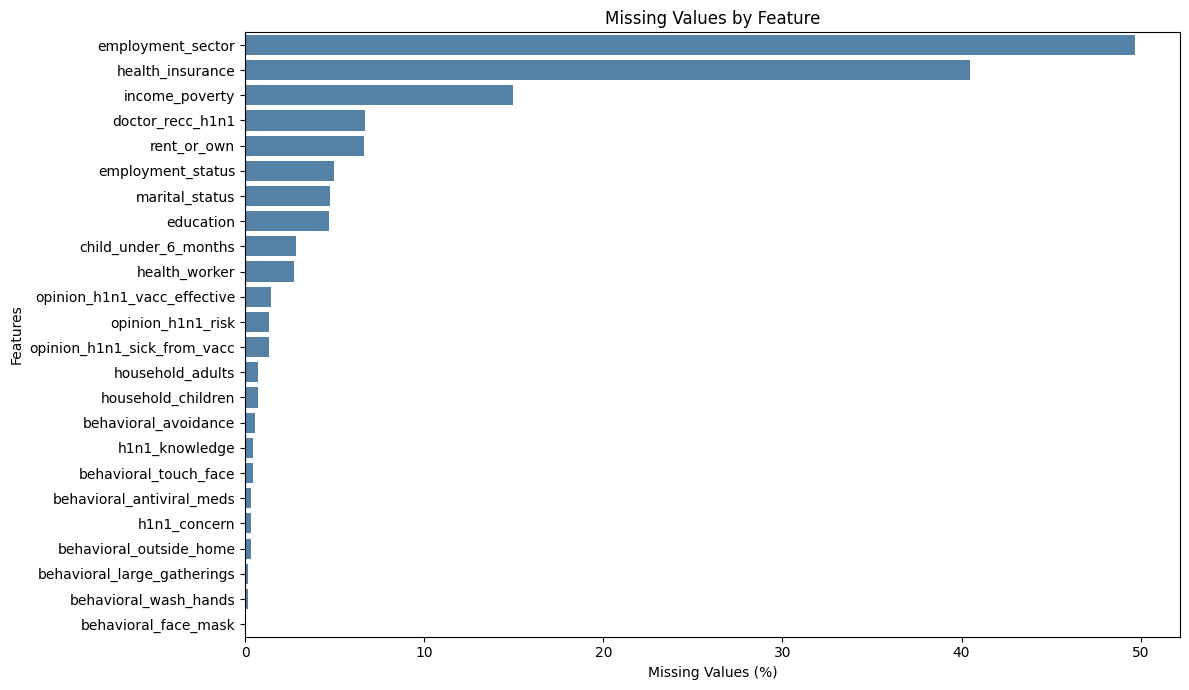

In [6]:

missing = train_df.isnull().sum()
missing = missing[missing > 0].sort_values(ascending=False)

missing_percent = (
    missing / len(train_df) * 100
).round(2)

missing_table = pd.DataFrame({
    "Missing Count": missing,
    "Missing Percentage": missing_percent
})

display(missing_table)

plt.figure(figsize=(12, 7))
sns.barplot(
    x=missing_table["Missing Percentage"],
    y=missing_table.index,
    color="steelblue"
)

plt.title("Missing Values by Feature")
plt.xlabel("Missing Values (%)")
plt.ylabel("Features")
plt.tight_layout()
plt.show()


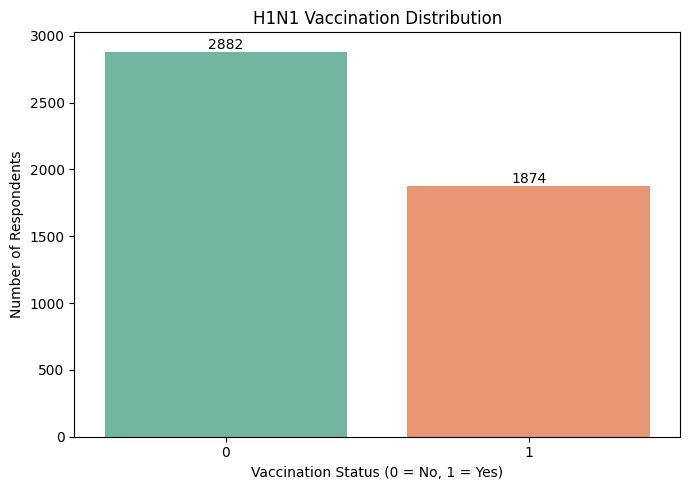

In [7]:

plt.figure(figsize=(7, 5))

ax = sns.countplot(
    data=train_df,
    x="h1n1_vaccine",
    hue="h1n1_vaccine",
    palette="Set2",
    legend=False
)

for container in ax.containers:
    ax.bar_label(container)

plt.title("H1N1 Vaccination Distribution")
plt.xlabel("Vaccination Status (0 = No, 1 = Yes)")
plt.ylabel("Number of Respondents")
plt.tight_layout()
plt.show()


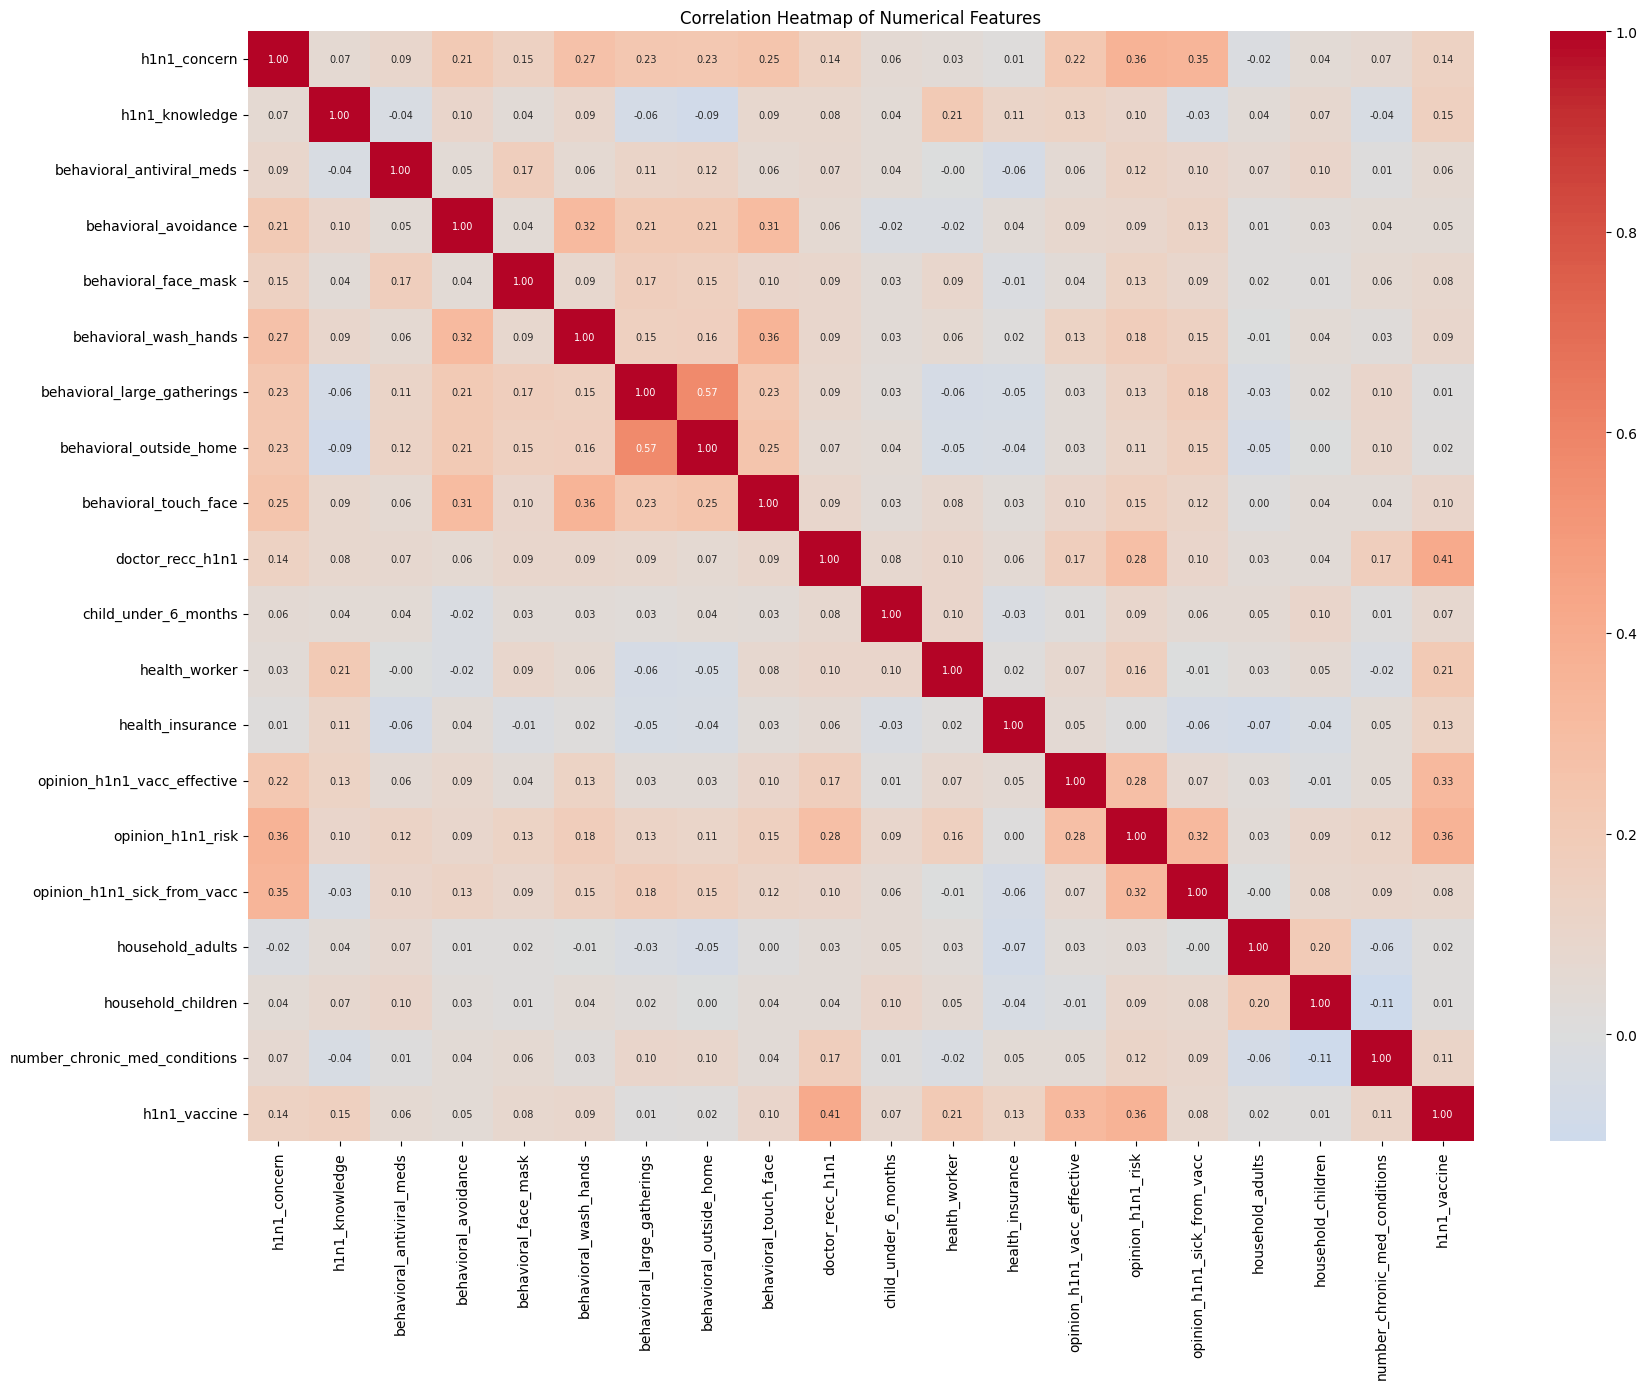

In [8]:

numeric_df = train_df.drop(
    columns=["respondent_id"],
    errors="ignore"
).select_dtypes(include=np.number)

plt.figure(figsize=(18, 14))

sns.heatmap(
    numeric_df.corr(),
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    annot_kws={"size": 7}
)

plt.title("Correlation Heatmap of Numerical Features")
plt.xticks(rotation=90)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()


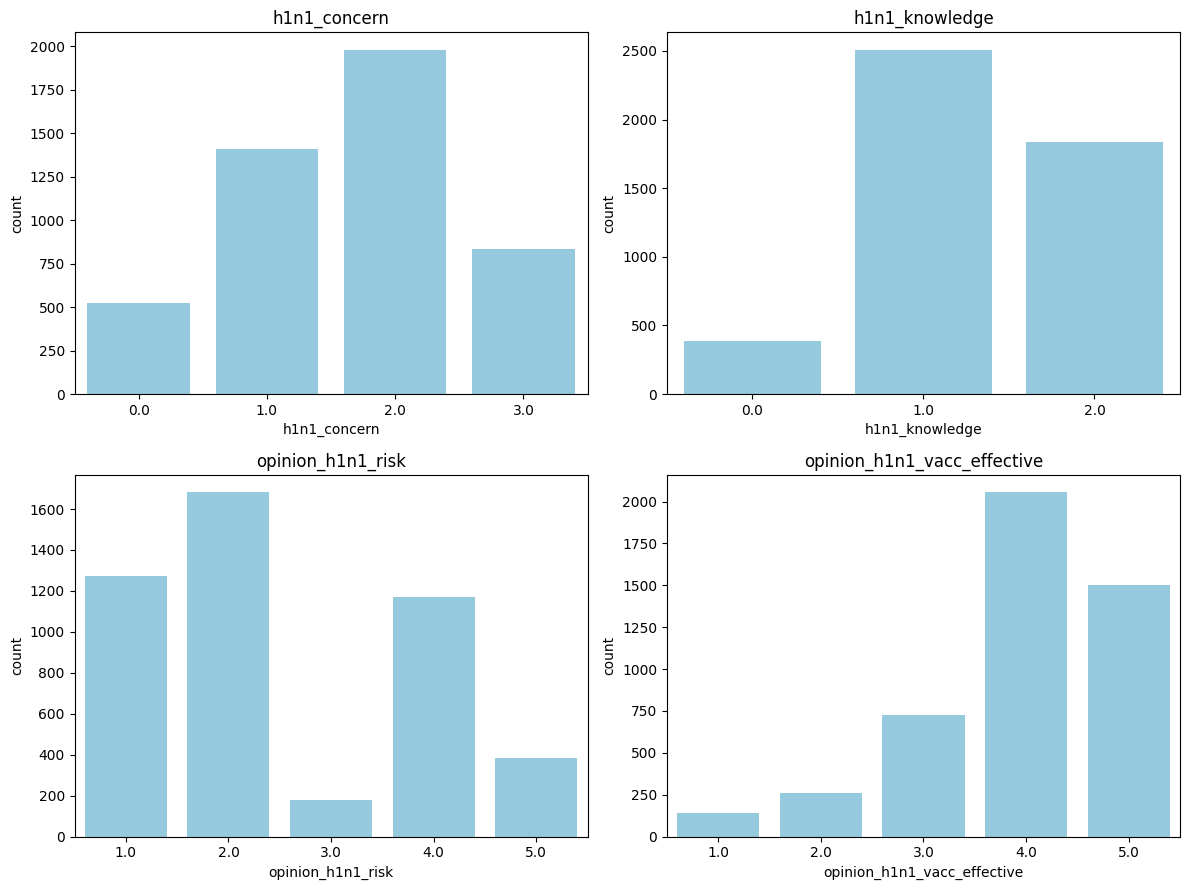

In [9]:

features = [
    "h1n1_concern",
    "h1n1_knowledge",
    "opinion_h1n1_risk",
    "opinion_h1n1_vacc_effective"
]

fig, axes = plt.subplots(2, 2, figsize=(12, 9))

for ax, feature in zip(axes.flatten(), features):
    sns.countplot(
        data=train_df,
        x=feature,
        color="skyblue",
        ax=ax
    )
    ax.set_title(feature)

plt.tight_layout()
plt.show()


In [10]:

X = train_df.drop(
    columns=["respondent_id", "h1n1_vaccine"]
)

y = train_df["h1n1_vaccine"]

X_test = test_df.drop(
    columns=["respondent_id"]
)

# Ensure matching feature columns
X_test = X_test[X.columns]

print("Training features:", X.shape)
print("Target:", y.shape)
print("Testing features:", X_test.shape)


Training features: (4756, 29)
Target: (4756,)
Testing features: (4749, 29)


In [11]:

categorical_cols = X.select_dtypes(
    include=["object", "category"]
).columns.tolist()

numerical_cols = X.select_dtypes(
    include=np.number
).columns.tolist()

print("Categorical Features:", categorical_cols)
print("\nNumerical Features:", numerical_cols)


Categorical Features: ['age_group', 'education', 'race', 'sex', 'income_poverty', 'marital_status', 'rent_or_own', 'employment_status', 'census_msa', 'employment_sector']

Numerical Features: ['h1n1_concern', 'h1n1_knowledge', 'behavioral_antiviral_meds', 'behavioral_avoidance', 'behavioral_face_mask', 'behavioral_wash_hands', 'behavioral_large_gatherings', 'behavioral_outside_home', 'behavioral_touch_face', 'doctor_recc_h1n1', 'child_under_6_months', 'health_worker', 'health_insurance', 'opinion_h1n1_vacc_effective', 'opinion_h1n1_risk', 'opinion_h1n1_sick_from_vacc', 'household_adults', 'household_children', 'number_chronic_med_conditions']


In [12]:

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(
        handle_unknown="ignore"
    ))
])

preprocessor = ColumnTransformer([
    ("num", numeric_pipeline, numerical_cols),
    ("cat", categorical_pipeline, categorical_cols)
])

print("Preprocessing pipeline created successfully.")


Preprocessing pipeline created successfully.


In [13]:

from sklearn.model_selection import train_test_split

X_train, X_val, y_train, y_val = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

X_train_processed = preprocessor.fit_transform(X_train)
X_val_processed = preprocessor.transform(X_val)

print("Processed Training:", X_train_processed.shape)
print("Processed Validation:", X_val_processed.shape)


Processed Training: (3804, 67)
Processed Validation: (952, 67)


In [14]:

feature_names = preprocessor.get_feature_names_out()

X_train_clean = pd.DataFrame(
    X_train_processed.toarray()
    if hasattr(X_train_processed, "toarray")
    else X_train_processed,
    columns=feature_names
)

print("Remaining Missing Values:",
      X_train_clean.isnull().sum().sum())

print("Processed Dataset Shape:", X_train_clean.shape)

display(X_train_clean.head())


Remaining Missing Values: 0
Processed Dataset Shape: (3804, 67)


,num__h1n1_concern,num__h1n1_knowledge,num__behavioral_antiviral_meds,num__behavioral_avoidance,num__behavioral_face_mask,num__behavioral_wash_hands,num__behavioral_large_gatherings,num__behavioral_outside_home,num__behavioral_touch_face,num__doctor_recc_h1n1,...,cat__employment_sector_media,cat__employment_sector_mining,cat__employment_sector_real_estate,cat__employment_sector_retail,cat__employment_sector_science,cat__employment_sector_services,cat__employment_sector_technology,cat__employment_sector_transportation,cat__employment_sector_utilities,cat__employment_sector_wholesale
0,-0.744109,-0.496203,-0.247758,0.581802,-0.293132,-2.30856,-0.760111,-0.719692,0.645978,-0.606104,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,0.383167,-0.496203,-0.247758,0.581802,-0.293132,0.43317,-0.760111,-0.719692,0.645978,1.649883,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,1.510444,1.138045,-0.247758,0.581802,-0.293132,0.43317,-0.760111,-0.719692,0.645978,-0.606104,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,-0.744109,-0.496203,-0.247758,-1.718797,-0.293132,-2.30856,-0.760111,-0.719692,-1.548040,-0.606104,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0
4,-0.744109,-0.496203,-0.247758,0.581802,-0.293132,0.43317,-0.760111,1.389483,0.645978,-0.606104,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0


In [15]:

# Fit on all labelled training rows for final model training
preprocessor.fit(X)

X_full_processed = preprocessor.transform(X)
X_submission_processed = preprocessor.transform(X_test)

import joblib

joblib.dump(preprocessor, "/content/preprocessor_B.joblib")

def save_processed(data, path, ids, target=None):
    columns = preprocessor.get_feature_names_out()

    if hasattr(data, "toarray"):
        data = data.toarray()

    df_out = pd.DataFrame(data, columns=columns)
    df_out.insert(0, "respondent_id", ids.to_numpy())

    if target is not None:
        df_out["h1n1_vaccine"] = target.to_numpy()

    df_out.to_csv(path, index=False)
    print("Saved:", path)

save_processed(
    X_full_processed,
    "/content/B_training_preprocessed.csv",
    train_df["respondent_id"],
    y
)

save_processed(
    X_submission_processed,
    "/content/B_testing_preprocessed.csv",
    test_df["respondent_id"]
)


Saved: /content/B_training_preprocessed.csv
Saved: /content/B_testing_preprocessed.csv


In [16]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay
)


In [18]:

train_df = pd.read_csv(
    "/content/sample_data/dataset_B_training.csv"
)

test_df = pd.read_csv(
    "/content/sample_data/dataset_B_testing.csv"
)

train_df.columns = train_df.columns.str.strip()
test_df.columns = test_df.columns.str.strip()

print("Training Shape:", train_df.shape)
print("Testing Shape:", test_df.shape)

display(train_df.head())


Training Shape: (4756, 31)
Testing Shape: (4749, 30)


,respondent_id,h1n1_concern,h1n1_knowledge,behavioral_antiviral_meds,behavioral_avoidance,behavioral_face_mask,behavioral_wash_hands,behavioral_large_gatherings,behavioral_outside_home,behavioral_touch_face,...,income_poverty,marital_status,rent_or_own,employment_status,census_msa,household_adults,household_children,employment_sector,number_chronic_med_conditions,h1n1_vaccine
0,1,1.0,2.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,...,"<= $75,000, Above Poverty",Married,Own,Employed,"MSA, Not Principle City",2.0,1.0,science,0,0
1,2,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,Below Poverty,Not Married,Own,Employed,Non-MSA,0.0,3.0,wholesale,0,0
2,3,2.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,...,"> $75,000",Not Married,Own,Employed,"MSA, Principle City",0.0,0.0,education,0,1
3,4,0.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,...,"<= $75,000, Above Poverty",Not Married,Rent,Not in Labor Force,Non-MSA,0.0,0.0,NaN,0,0
4,5,2.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,NaN,Not Married,NaN,Unemployed,Non-MSA,3.0,0.0,NaN,0,0


In [19]:

target = "h1n1_vaccine"

X = train_df.drop(
    columns=["respondent_id", target]
)

y = train_df[target]

X_test = test_df.drop(
    columns=["respondent_id"]
)

# Check feature consistency
missing = set(X.columns) - set(X_test.columns)
extra = set(X_test.columns) - set(X.columns)

print("Missing Testing Features:", missing)
print("Extra Testing Features:", extra)

if missing or extra:
    raise ValueError(
        "Training and testing features do not match."
    )

X_test = X_test[X.columns]

print("X Shape:", X.shape)
print("y Shape:", y.shape)
print("Test Shape:", X_test.shape)


Missing Testing Features: set()
Extra Testing Features: set()
X Shape: (4756, 29)
y Shape: (4756,)
Test Shape: (4749, 29)


In [20]:

X_train, X_val, y_train, y_val = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

numeric_cols = X.select_dtypes(
    include=np.number
).columns.tolist()

categorical_cols = X.select_dtypes(
    exclude=np.number
).columns.tolist()

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("num", numeric_pipeline, numeric_cols),
    ("cat", categorical_pipeline, categorical_cols)
])

print("Training:", X_train.shape)
print("Validation:", X_val.shape)


Training: (3804, 29)
Validation: (952, 29)


In [21]:

models = {
    "Logistic Regression": LogisticRegression(
        max_iter=2000,
        random_state=42
    ),

    "Decision Tree": DecisionTreeClassifier(
        max_depth=8,
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        random_state=42,
        n_jobs=-1
    ),

    "SVM": SVC(
        kernel="rbf",
        probability=True,
        random_state=42
    )
}

trained_models = {}

for name, model in models.items():

    pipeline = Pipeline([
        ("preprocessing", preprocessor),
        ("classifier", model)
    ])

    pipeline.fit(X_train, y_train)

    trained_models[name] = pipeline

    print(name, "Training Completed")


Logistic Regression Training Completed
Decision Tree Training Completed
Random Forest Training Completed
SVM Training Completed


In [22]:

results = []

for name, model in trained_models.items():

    y_pred = model.predict(X_val)
    y_prob = model.predict_proba(X_val)[:, 1]

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_val, y_pred),
        "Precision": precision_score(
            y_val, y_pred, zero_division=0
        ),
        "Recall": recall_score(
            y_val, y_pred, zero_division=0
        ),
        "F1 Score": f1_score(
            y_val, y_pred, zero_division=0
        ),
        "ROC AUC": roc_auc_score(y_val, y_prob)
    })

results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by="ROC AUC",
    ascending=False
)

display(results_df.round(4))


,Model,Accuracy,Precision,Recall,F1 Score,ROC AUC
0,Logistic Regression,0.7605,0.7290,0.6240,0.6724,0.8166
3,SVM,0.7563,0.7187,0.6267,0.6695,0.8051
2,Random Forest,0.7542,0.7196,0.6160,0.6638,0.7965
1,Decision Tree,0.7290,0.6736,0.6053,0.6376,0.7666


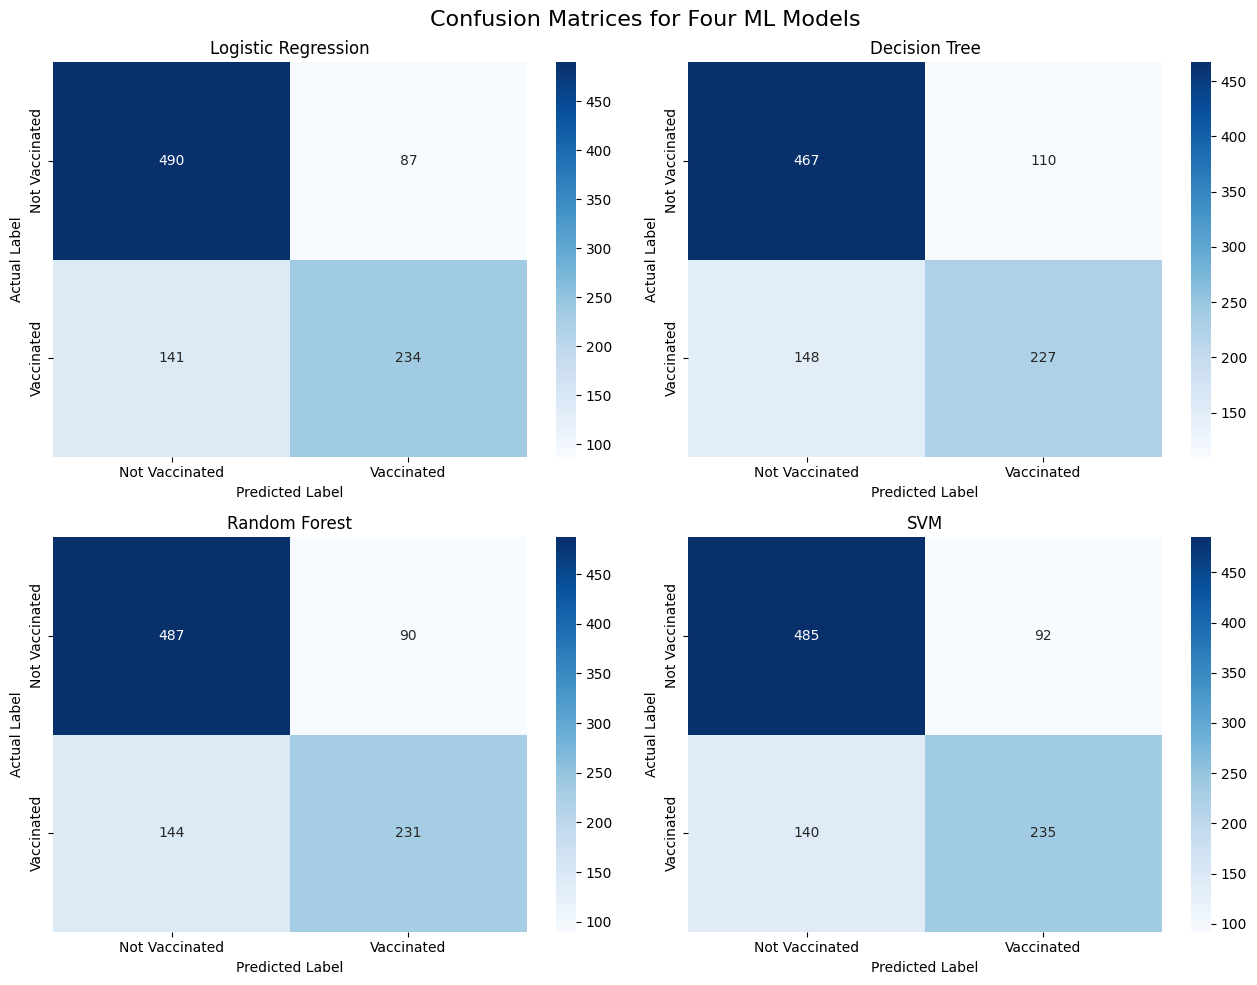

In [23]:

fig, axes = plt.subplots(2, 2, figsize=(13, 10))

for ax, (name, model) in zip(
    axes.flatten(),
    trained_models.items()
):

    y_pred = model.predict(X_val)

    cm = confusion_matrix(
        y_val,
        y_pred,
        labels=[0, 1]
    )

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=["Not Vaccinated", "Vaccinated"],
        yticklabels=["Not Vaccinated", "Vaccinated"],
        ax=ax
    )

    ax.set_title(name)
    ax.set_xlabel("Predicted Label")
    ax.set_ylabel("Actual Label")

plt.suptitle(
    "Confusion Matrices for Four ML Models",
    fontsize=16
)

plt.tight_layout()
plt.show()


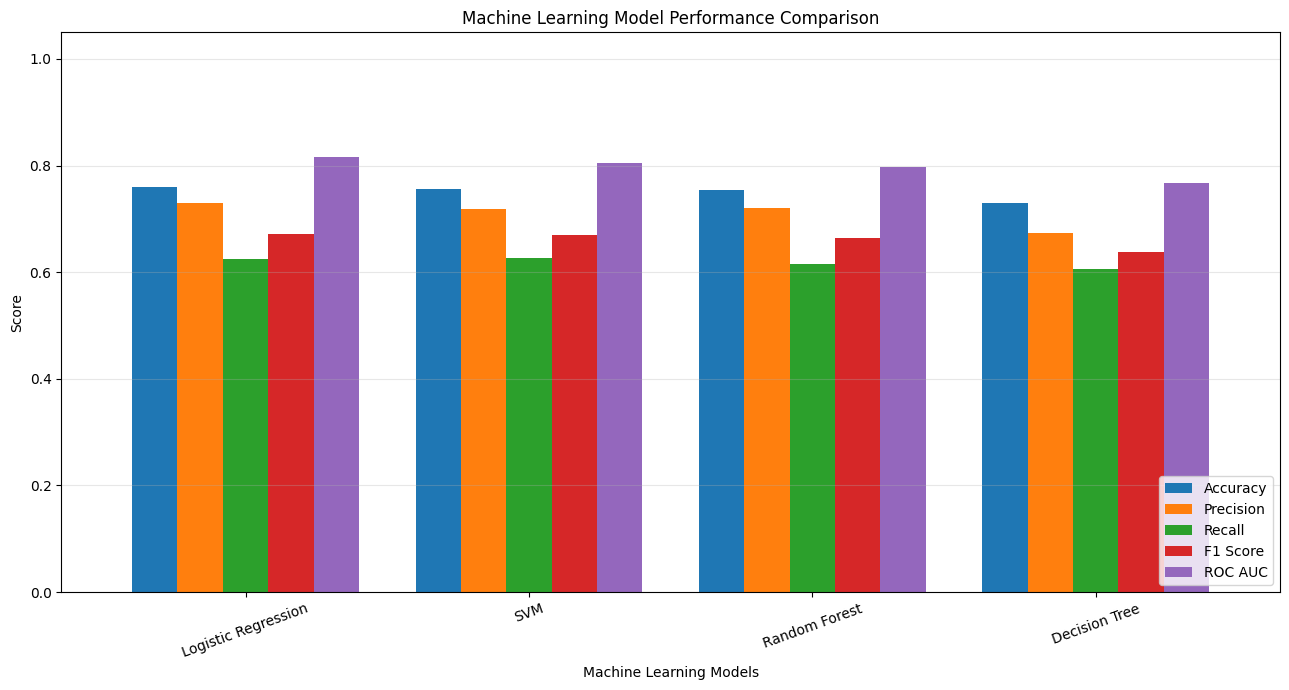

In [24]:

metrics_df = results_df.set_index("Model")

metrics_df.plot(
    kind="bar",
    figsize=(13, 7),
    width=0.8
)

plt.title("Machine Learning Model Performance Comparison")
plt.xlabel("Machine Learning Models")
plt.ylabel("Score")
plt.ylim(0, 1.05)
plt.xticks(rotation=20)
plt.legend(loc="lower right")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()



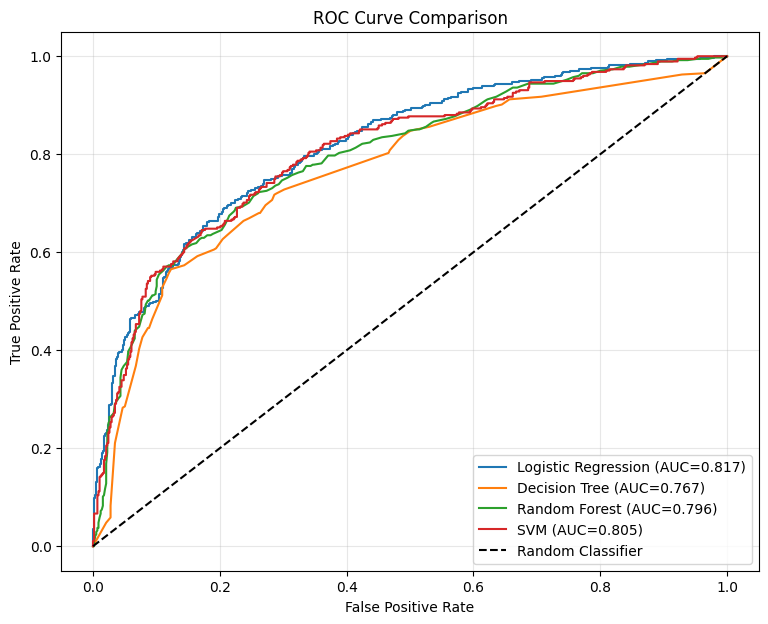

In [26]:

from sklearn.metrics import roc_curve

plt.figure(figsize=(9, 7))

for name, model in trained_models.items():

    y_prob = model.predict_proba(X_val)[:, 1]

    fpr, tpr, thresholds = roc_curve(
        y_val,
        y_prob
    )

    auc_score = roc_auc_score(y_val, y_prob)

    plt.plot(
        fpr,
        tpr,
        label=f"{name} (AUC={auc_score:.3f})"
    )

plt.plot(
    [0, 1],
    [0, 1],
    "k--",
    label="Random Classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve Comparison")
plt.legend()
plt.grid(alpha=0.3)
plt.show()


In [27]:

best_model_name = results_df.iloc[0]["Model"]

best_model = trained_models[best_model_name]

print("Best Performing Model:", best_model_name)

print("\nPerformance:")
display(results_df.iloc[[0]])

print("\nClassification Report:")
print(
    classification_report(
        y_val,
        best_model.predict(X_val),
        zero_division=0
    )
)


Best Performing Model: Logistic Regression

Performance:


,Model,Accuracy,Precision,Recall,F1 Score,ROC AUC
0,Logistic Regression,0.760504,0.728972,0.624,0.672414,0.816555



Classification Report:
              precision    recall  f1-score   support

           0       0.78      0.85      0.81       577
           1       0.73      0.62      0.67       375

    accuracy                           0.76       952
   macro avg       0.75      0.74      0.74       952
weighted avg       0.76      0.76      0.76       952



In [28]:

from sklearn.base import clone

final_model = clone(best_model)

final_model.fit(X, y)

test_predictions = final_model.predict(X_test)

submission = pd.DataFrame({
    "respondent_id": test_df["respondent_id"],
    "h1n1_vaccine": test_predictions
})

submission.to_csv(
    "/content/dataset_B_submission.csv",
    index=False
)

print("Submission File Created Successfully!")
display(submission.head())

from google.colab import files
files.download("/content/dataset_B_submission.csv")


Submission File Created Successfully!


,respondent_id,h1n1_vaccine
0,4757,0
1,4758,0
2,4759,0
3,4760,0
4,4761,0


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [29]:

results_df.to_csv(
    "/content/model_performance.csv",
    index=False
)

import joblib

joblib.dump(
    final_model,
    "/content/best_model.pkl"
)

print("Model comparison and best model saved.")


Model comparison and best model saved.


In [30]:

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix
)

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

performance_results = []

for name, model in trained_models.items():

    y_pred = model.predict(X_val)
    y_prob = model.predict_proba(X_val)[:, 1]

    performance_results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_val, y_pred),
        "Precision": precision_score(
            y_val, y_pred, zero_division=0
        ),
        "Recall": recall_score(
            y_val, y_pred, zero_division=0
        ),
        "F1 Score": f1_score(
            y_val, y_pred, zero_division=0
        ),
        "ROC AUC": roc_auc_score(y_val, y_prob)
    })

performance_df = pd.DataFrame(performance_results)

display(performance_df.round(4))


,Model,Accuracy,Precision,Recall,F1 Score,ROC AUC
0,Logistic Regression,0.7605,0.7290,0.6240,0.6724,0.8166
1,Decision Tree,0.7290,0.6736,0.6053,0.6376,0.7666
2,Random Forest,0.7542,0.7196,0.6160,0.6638,0.7965
3,SVM,0.7563,0.7187,0.6267,0.6695,0.8051


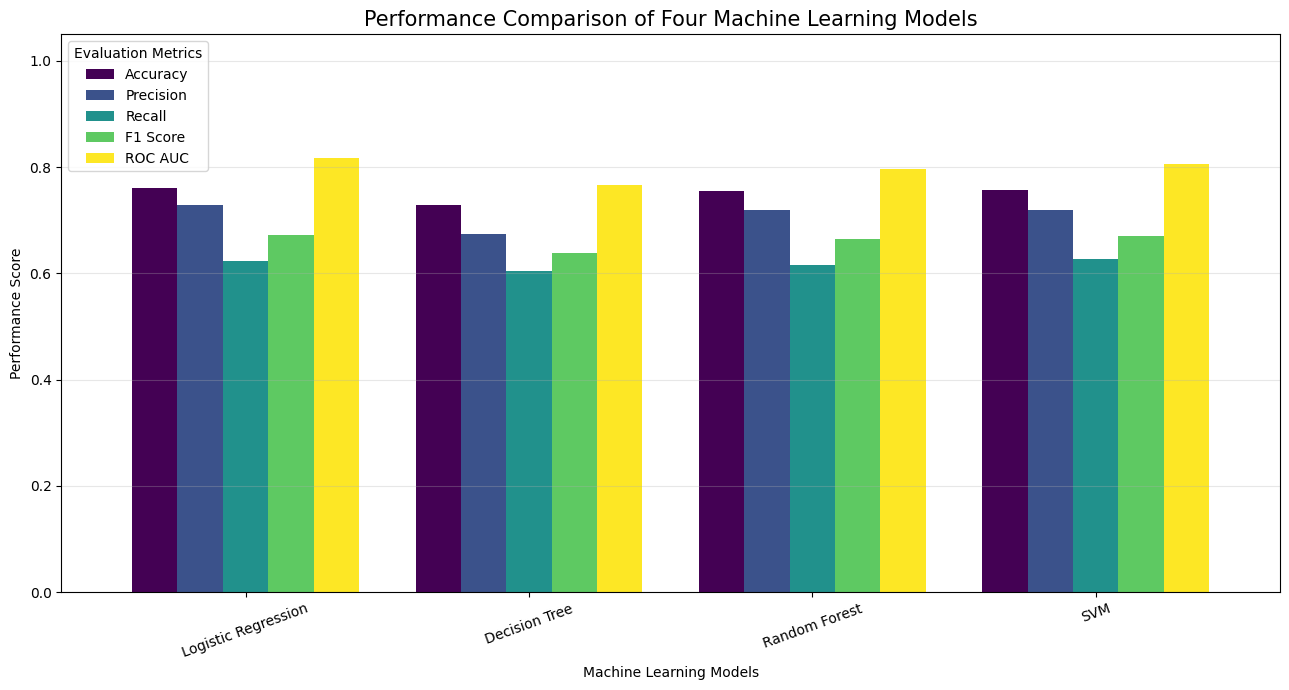

In [31]:

performance_df.set_index("Model").plot(
    kind="bar",
    figsize=(13, 7),
    width=0.8,
    colormap="viridis"
)

plt.title(
    "Performance Comparison of Four Machine Learning Models",
    fontsize=15
)

plt.xlabel("Machine Learning Models")
plt.ylabel("Performance Score")
plt.ylim(0, 1.05)
plt.xticks(rotation=20)
plt.legend(title="Evaluation Metrics")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


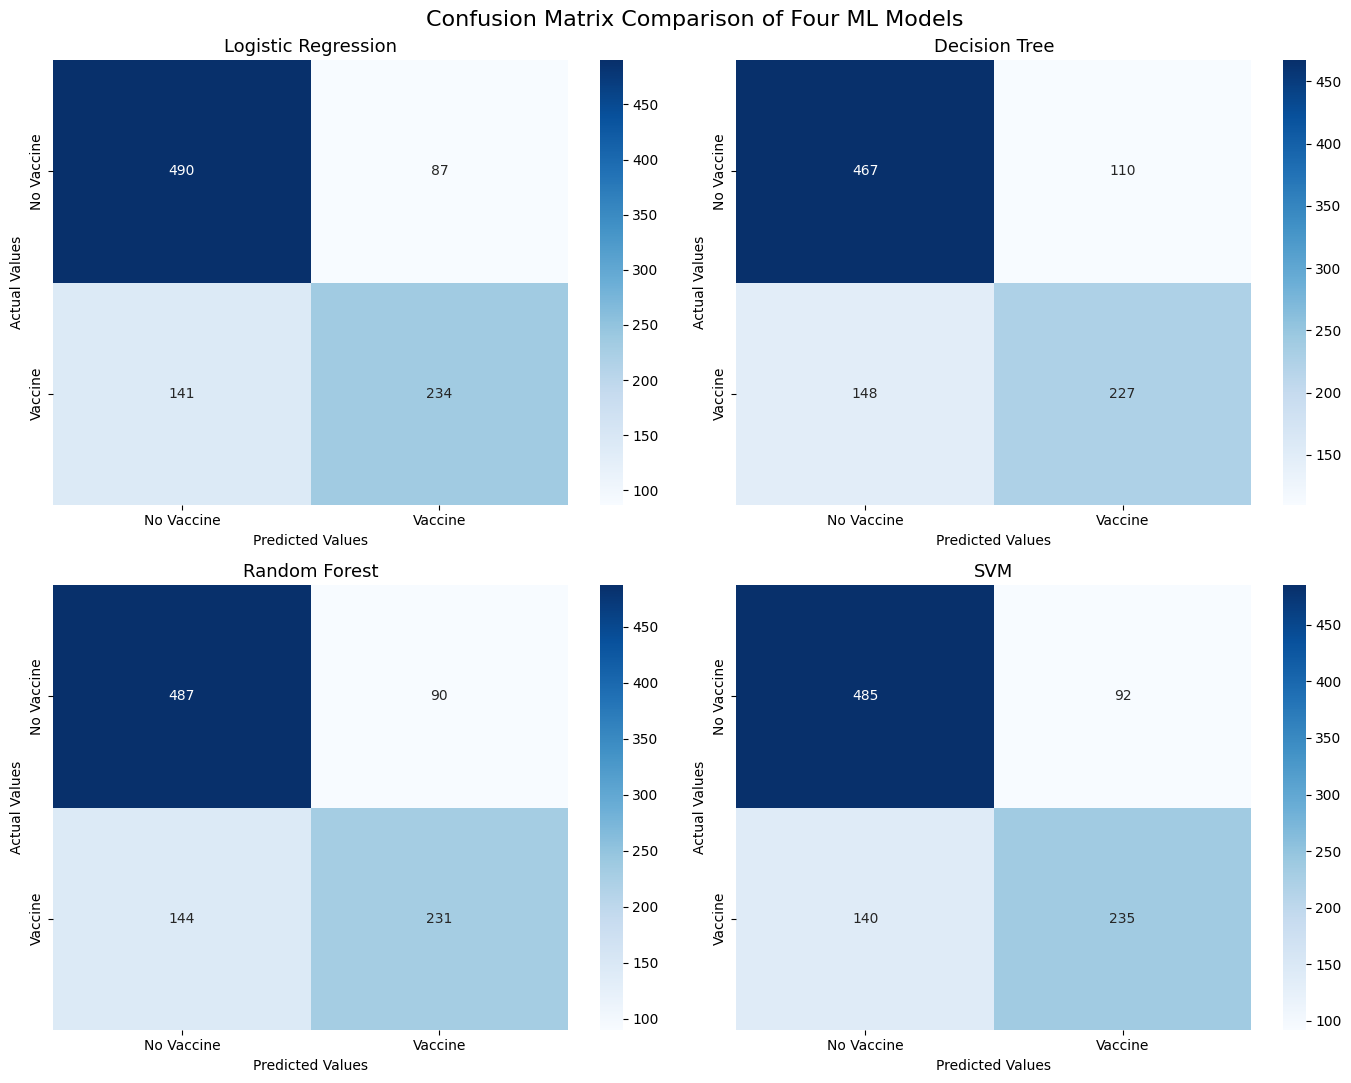

In [32]:

fig, axes = plt.subplots(2, 2, figsize=(14, 11))

for ax, (name, model) in zip(
    axes.flatten(),
    trained_models.items()
):

    y_pred = model.predict(X_val)

    cm = confusion_matrix(
        y_val,
        y_pred,
        labels=[0, 1]
    )

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=["No Vaccine", "Vaccine"],
        yticklabels=["No Vaccine", "Vaccine"],
        ax=ax
    )

    ax.set_title(name, fontsize=13)
    ax.set_xlabel("Predicted Values")
    ax.set_ylabel("Actual Values")

plt.suptitle(
    "Confusion Matrix Comparison of Four ML Models",
    fontsize=16
)

plt.tight_layout()
plt.show()


In [33]:

for name, model in trained_models.items():

    y_pred = model.predict(X_val)

    print("=" * 60)
    print("MODEL:", name)
    print("=" * 60)

    print(
        classification_report(
            y_val,
            y_pred,
            target_names=[
                "Not Vaccinated",
                "Vaccinated"
            ],
            zero_division=0
        )
    )


MODEL: Logistic Regression
                precision    recall  f1-score   support

Not Vaccinated       0.78      0.85      0.81       577
    Vaccinated       0.73      0.62      0.67       375

      accuracy                           0.76       952
     macro avg       0.75      0.74      0.74       952
  weighted avg       0.76      0.76      0.76       952

MODEL: Decision Tree
                precision    recall  f1-score   support

Not Vaccinated       0.76      0.81      0.78       577
    Vaccinated       0.67      0.61      0.64       375

      accuracy                           0.73       952
     macro avg       0.72      0.71      0.71       952
  weighted avg       0.73      0.73      0.73       952

MODEL: Random Forest
                precision    recall  f1-score   support

Not Vaccinated       0.77      0.84      0.81       577
    Vaccinated       0.72      0.62      0.66       375

      accuracy                           0.75       952
     macro avg       0.75  

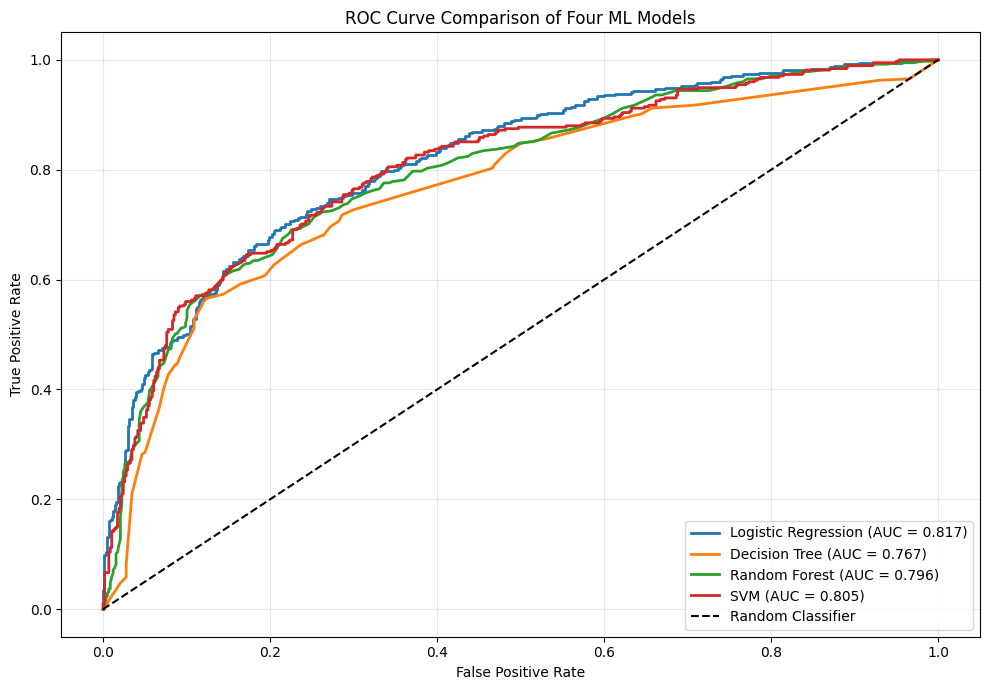

In [34]:

from sklearn.metrics import roc_curve, auc

plt.figure(figsize=(10, 7))

for name, model in trained_models.items():

    y_prob = model.predict_proba(X_val)[:, 1]

    fpr, tpr, _ = roc_curve(y_val, y_prob)

    roc_auc = auc(fpr, tpr)

    plt.plot(
        fpr,
        tpr,
        linewidth=2,
        label=f"{name} (AUC = {roc_auc:.3f})"
    )

plt.plot(
    [0, 1],
    [0, 1],
    "k--",
    label="Random Classifier"
)

plt.title("ROC Curve Comparison of Four ML Models")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()





,Model,Training Accuracy,Validation Accuracy,Accuracy Gap
0,Logistic Regression,0.7805,0.7605,0.0200
1,Decision Tree,0.8197,0.7290,0.0907
2,Random Forest,1.0000,0.7542,0.2458
3,SVM,0.8354,0.7563,0.0791


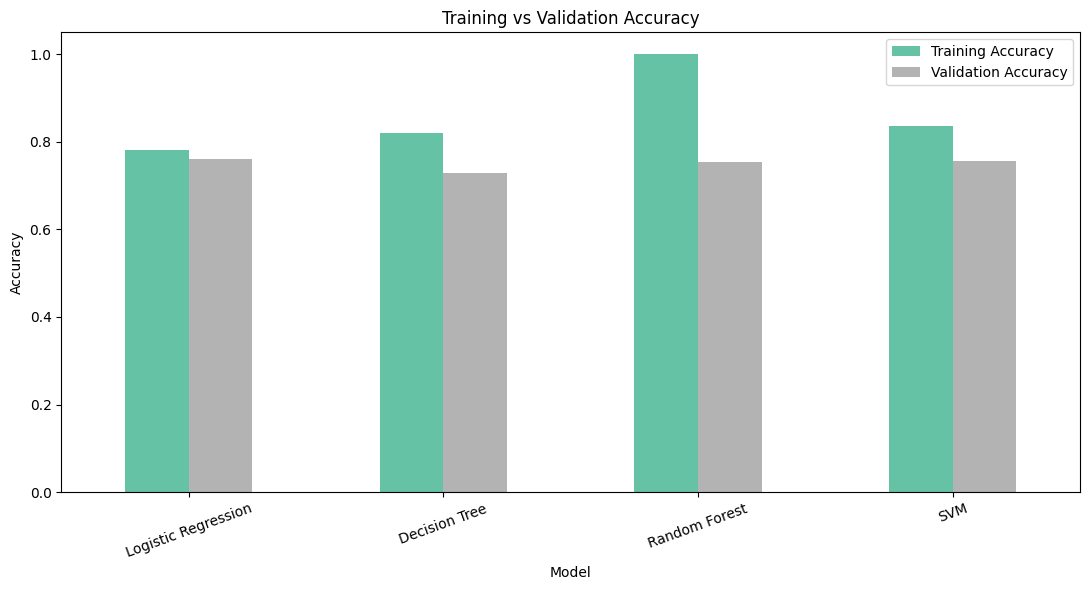

In [35]:

accuracy_comparison = []

for name, model in trained_models.items():

    train_accuracy = accuracy_score(
        y_train,
        model.predict(X_train)
    )

    validation_accuracy = accuracy_score(
        y_val,
        model.predict(X_val)
    )

    accuracy_comparison.append({
        "Model": name,
        "Training Accuracy": train_accuracy,
        "Validation Accuracy": validation_accuracy,
        "Accuracy Gap": train_accuracy - validation_accuracy
    })

accuracy_df = pd.DataFrame(accuracy_comparison)

display(accuracy_df.round(4))

accuracy_df.set_index("Model")[
    ["Training Accuracy", "Validation Accuracy"]
].plot(
    kind="bar",
    figsize=(11, 6),
    colormap="Set2"
)

plt.title("Training vs Validation Accuracy")
plt.ylabel("Accuracy")
plt.ylim(0, 1.05)
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()


In [36]:

performance_df = performance_df.sort_values(
    by="ROC AUC",
    ascending=False
)

best_model_name = performance_df.iloc[0]["Model"]

print("BEST PERFORMING MODEL:", best_model_name)

print("\nBest Model Performance:")
display(performance_df.head(1).round(4))

print("\nOverall Model Ranking:")
display(performance_df.round(4))


BEST PERFORMING MODEL: Logistic Regression

Best Model Performance:


,Model,Accuracy,Precision,Recall,F1 Score,ROC AUC
0,Logistic Regression,0.7605,0.729,0.624,0.6724,0.8166



Overall Model Ranking:


,Model,Accuracy,Precision,Recall,F1 Score,ROC AUC
0,Logistic Regression,0.7605,0.7290,0.6240,0.6724,0.8166
3,SVM,0.7563,0.7187,0.6267,0.6695,0.8051
2,Random Forest,0.7542,0.7196,0.6160,0.6638,0.7965
1,Decision Tree,0.7290,0.6736,0.6053,0.6376,0.7666


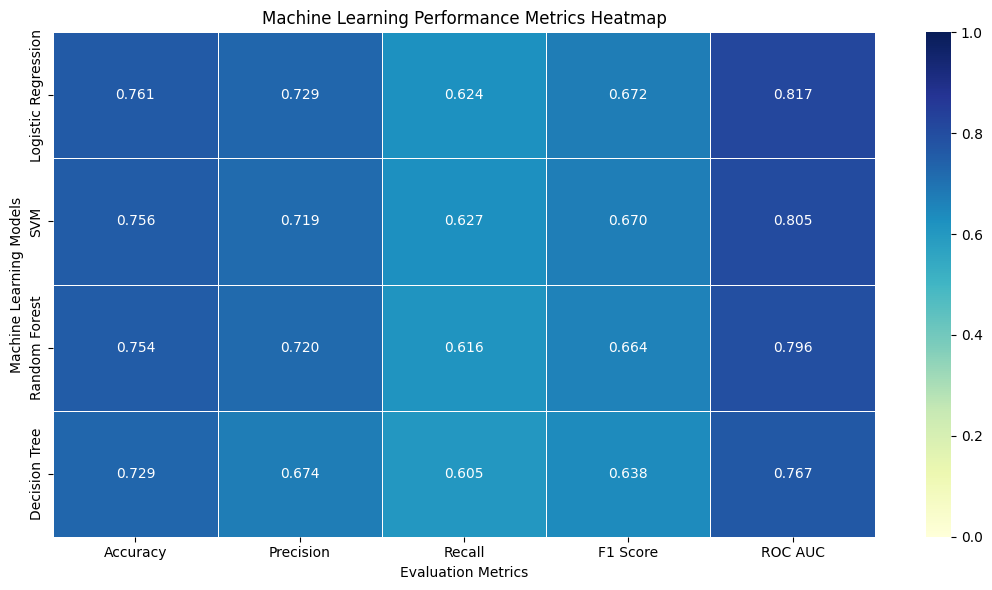

In [37]:

heatmap_data = performance_df.set_index("Model")

plt.figure(figsize=(11, 6))

sns.heatmap(
    heatmap_data,
    annot=True,
    fmt=".3f",
    cmap="YlGnBu",
    linewidths=0.5,
    vmin=0,
    vmax=1
)

plt.title("Machine Learning Performance Metrics Heatmap")
plt.xlabel("Evaluation Metrics")
plt.ylabel("Machine Learning Models")
plt.tight_layout()
plt.show()


In [38]:

performance_df.to_csv(
    "/content/dataset_B_performance_analysis.csv",
    index=False
)

accuracy_df.to_csv(
    "/content/dataset_B_training_validation_accuracy.csv",
    index=False
)

print("Performance analysis files saved successfully!")

from google.colab import files

files.download(
    "/content/dataset_B_performance_analysis.csv"
)


Performance analysis files saved successfully!


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [39]:

best = performance_df.iloc[0]

print("PERFORMANCE ANALYSIS CONCLUSION")
print("=" * 60)

print(
    f"Four machine learning models were evaluated "
    f"for H1N1 vaccination prediction."
)

print(
    f"The highest validation ROC-AUC was achieved "
    f"by {best['Model']}."
)

print(f"Accuracy: {best['Accuracy']:.4f}")
print(f"Precision: {best['Precision']:.4f}")
print(f"Recall: {best['Recall']:.4f}")
print(f"F1 Score: {best['F1 Score']:.4f}")
print(f"ROC-AUC: {best['ROC AUC']:.4f}")

print(
    "\nThe selected model achieved the strongest "
    "ROC-AUC on the validation dataset. "
    "Further cross-validation and hyperparameter "
    "tuning are recommended to assess robustness."
)


PERFORMANCE ANALYSIS CONCLUSION
Four machine learning models were evaluated for H1N1 vaccination prediction.
The highest validation ROC-AUC was achieved by Logistic Regression.
Accuracy: 0.7605
Precision: 0.7290
Recall: 0.6240
F1 Score: 0.6724
ROC-AUC: 0.8166

The selected model achieved the strongest ROC-AUC on the validation dataset. Further cross-validation and hyperparameter tuning are recommended to assess robustness.


In [40]:

import pandas as pd
import os

from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.ensemble import GradientBoostingClassifier
from google.colab import files

# Create output folder
os.makedirs("/content/submissions", exist_ok=True)

# Add fifth model
all_models = dict(trained_models)

all_models["Gradient Boosting"] = Pipeline([
    ("preprocessing", preprocessor),
    ("classifier", GradientBoostingClassifier(
        n_estimators=100,
        random_state=42
    ))
])

# Generate 5 CSV submission files
for name, model in all_models.items():

    # Retrain on full labelled dataset
    final_model = clone(model)
    final_model.fit(X, y)

    # Predict probability of vaccination
    predictions = final_model.predict_proba(X_test)[:, 1]

    submission = pd.DataFrame({
        "respondent_id": test_df["respondent_id"],
        "h1n1_vaccine": predictions
    })

    filename = (
        name.lower().replace(" ", "_")
        + "_submission.csv"
    )

    filepath = "/content/submissions/" + filename

    submission.to_csv(filepath, index=False)

    print("Created:", filename)

print("\nAll 5 CSV files generated successfully!")


Created: logistic_regression_submission.csv
Created: decision_tree_submission.csv
Created: random_forest_submission.csv
Created: svm_submission.csv
Created: gradient_boosting_submission.csv

All 5 CSV files generated successfully!


In [41]:

import glob

csv_files = sorted(
    glob.glob("/content/submissions/*.csv")
)

for file in csv_files:
    print("\nFile:", os.path.basename(file))
    display(pd.read_csv(file).head())



File: decision_tree_submission.csv


,respondent_id,h1n1_vaccine
0,4757,0.224053
1,4758,0.153846
2,4759,0.081356
3,4760,0.419753
4,4761,0.147727



File: gradient_boosting_submission.csv


,respondent_id,h1n1_vaccine
0,4757,0.176991
1,4758,0.129920
2,4759,0.101761
3,4760,0.185998
4,4761,0.103540



File: logistic_regression_submission.csv


,respondent_id,h1n1_vaccine
0,4757,0.200736
1,4758,0.063127
2,4759,0.081725
3,4760,0.190047
4,4761,0.099086



File: random_forest_submission.csv


,respondent_id,h1n1_vaccine
0,4757,0.280
1,4758,0.195
2,4759,0.030
3,4760,0.365
4,4761,0.055



File: svm_submission.csv


,respondent_id,h1n1_vaccine
0,4757,0.196000
1,4758,0.211896
2,4759,0.157652
3,4760,0.234252
4,4761,0.184167


In [42]:

import shutil

zip_path = shutil.make_archive(
    "/content/5_model_submissions",
    "zip",
    "/content/submissions"
)

files.download(zip_path)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [43]:
predictions = final_model.predict_proba(X_test)[:, 1]

In [44]:
predictions = final_model.predict(X_test)
